In [4]:
import os
import sys
import time
import json
import random
import platform
import itertools
import subprocess
import joblib
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from scipy.signal import welch
from tensorflow.keras import Sequential, Input, Model
from tensorflow.keras.layers import (Dense, Dropout, Conv1D, MaxPooling1D, Flatten, SimpleRNN, LSTM, GRU,
                                     Add, Activation, GlobalAveragePooling1D, MultiHeadAttention,
                                     LayerNormalization)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

In [5]:
# Constants
SEED = 42
DATA_FILE = "FordA_TRAIN.tsv"      # tab-separated, no header, column 0 = label (1 / -1), columns 1.. = series
TEST_SIZE = 0.20                   # share of the file held out for testing
VAL_SIZE = 0.20                    # share of the file used for validation (train gets the remaining 60%)
EPOCHS = 30
BATCH_SIZE = 32
PATIENCE = 5                       # per-trial early stopping on (window-level) validation loss
LEARNING_RATE = 0.001
CLASS_NAMES = ["No fault", "Fault"]
USE_GPU = True                     # True = use the NVIDIA GPU if TensorFlow can see one, False = force CPU
SAVE_FIGURES = True
CHECKPOINT_DIR = "checkpoints"

# Windowing
DEFAULT_WINDOW = 500               # window used for the model comparison (500 = the whole series, as in Stage 1)
WINDOW_SIZES = [100, 250, 500]     # window sizes searched during HPO
WINDOW_OVERLAP = 0.5               # 50% overlap between neighbouring windows (W = 500 gives a single window)
TCN_LEVELS = 4                     # TCN residual blocks, dilations 1, 2, 4, 8

# ---------------------------------------------------------------- HPO protocol (fixed BEFORE any trial is run)
# Which model is tuned : the model family with the best DEFAULT-config validation accuracy (ties: val AUC, then fewer params)
# Search space         : GRIDS below (window size + model-specific hyper-parameters); the default config is one grid point
# Objective            : series-level VALIDATION accuracy (higher is better); tie-break = fewer parameters
# Budget               : at most HPO_MAX_TRIALS trials and HPO_TIME_BUDGET_S seconds; trials run in a seeded random order
# Stopping rule        : stop when the grid is exhausted, or the trial cap is hit, or the time budget is spent;
#                        inside each trial: early stopping on validation loss (PATIENCE epochs, best weights restored)
# Data used            : train for fitting, validation for selection. The test set is NOT touched until section 15.
HPO_MAX_TRIALS = 24
HPO_TIME_BUDGET_S = 3600

# Grid search parameters
GRIDS = {
    "MLP": {"window": WINDOW_SIZES, "units": [32, 64, 128], "dropout": [0.0, 0.3]},
    "CNN": {"window": WINDOW_SIZES, "filters": [8, 16], "kernel_size": [3, 7]},
    "SimpleRNN": {"window": WINDOW_SIZES, "units": [16, 32], "dropout": [0.0, 0.3]},
    "LSTM": {"window": WINDOW_SIZES, "units": [16, 32], "dropout": [0.0, 0.3]},
    "GRU": {"window": WINDOW_SIZES, "units": [16, 32], "dropout": [0.0, 0.3]},
    "TCN": {"window": WINDOW_SIZES, "filters": [16, 32], "kernel_size": [3, 7]},
    "Transformer": {"window": WINDOW_SIZES, "d_model": [16, 32], "heads": [2, 4]},
}
DEFAULT_HP = {                     # same defaults as stage 1 for MLP / CNN
    "MLP": {"units": 64, "dropout": 0.0},
    "CNN": {"filters": 8, "kernel_size": 7},
    "SimpleRNN": {"units": 32, "dropout": 0.0},
    "LSTM": {"units": 32, "dropout": 0.0},
    "GRU": {"units": 32, "dropout": 0.0},
    "TCN": {"filters": 16, "kernel_size": 3},
    "Transformer": {"d_model": 32, "heads": 2},
}

In [6]:
# GPU setup
gpus = tf.config.list_physical_devices("GPU")
if USE_GPU and gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)    # don't grab all GPU memory up front
    DEVICE_NAME = "GPU: " + ", ".join(g.name for g in gpus)
else:
    if gpus:
        tf.config.set_visible_devices([], "GPU")               # USE_GPU = False -> hide the GPU
    DEVICE_NAME = "CPU"
    if USE_GPU:
        print("WARNING: no GPU visible to TensorFlow, running on CPU.\n"
              "  - Native Windows: TensorFlow >= 2.11 has no GPU support, use WSL2 (Ubuntu) or a Linux machine.\n"
              "  - Linux / WSL2: pip install 'tensorflow[and-cuda]' and make sure the NVIDIA driver works (nvidia-smi).")
print("TensorFlow", tf.__version__, "| running on", DEVICE_NAME)

tf.keras.utils.set_random_seed(SEED)

  - Native Windows: TensorFlow >= 2.11 has no GPU support, use WSL2 (Ubuntu) or a Linux machine.
  - Linux / WSL2: pip install 'tensorflow[and-cuda]' and make sure the NVIDIA driver works (nvidia-smi).
TensorFlow 2.22.0-rc0 | running on CPU


## 1. Problem and data

In [7]:
def load_forda(filename):
    # Load Tab separated value file
    data = pd.read_csv(filename, sep="\t", header=None).to_numpy(dtype=np.float32)
    raw_labels = data[:, 0]
    # Check if all rows are labelled with a 1/-1
    assert set(np.unique(raw_labels[~np.isnan(raw_labels)])) <= {-1.0, 1.0}, "labels must be 1 or -1"
    # Convert to 1 = fault, 0 = no fault (original -1)
    y = (raw_labels == 1).astype(int)
    return data[:, 1:], y


X_all, y_all = load_forda(DATA_FILE)
SERIES_LEN = X_all.shape[1]
assert max(WINDOW_SIZES + [DEFAULT_WINDOW]) <= SERIES_LEN, "window cannot be longer than the series"
print("Full file:", X_all.shape)

# Split SERIES indices (test first, then train / validation), stratified. Same seed, sizes and stratification as Stage 1,
# so the partition is the same; indices are kept so they can be saved with the checkpoint.
idx_all = np.arange(len(y_all))
idx_rest, idx_test = train_test_split(idx_all, test_size=TEST_SIZE, random_state=SEED, stratify=y_all)
idx_train, idx_val = train_test_split(idx_rest, test_size=VAL_SIZE / (1 - TEST_SIZE), random_state=SEED,
                                      stratify=y_all[idx_rest])

X_train_raw, y_train = X_all[idx_train], y_all[idx_train]
X_val_raw, y_val = X_all[idx_val], y_all[idx_val]
X_test_raw, y_test = X_all[idx_test], y_all[idx_test]
print("Train:", X_train_raw.shape, "| Val:", X_val_raw.shape, "| Test:", X_test_raw.shape)


Full file: (3601, 500)
Train: (2160, 500) | Val: (720, 500) | Test: (721, 500)


In [8]:
# Verify data splits
split_table = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "source": [f"{1 - VAL_SIZE - TEST_SIZE:.0%} of the file (fit models)",
               f"{VAL_SIZE:.0%} of the file (early stopping, HPO selection)",
               f"{TEST_SIZE:.0%} of the file (final evaluation only)"],
    "series": [len(X_train_raw), len(X_val_raw), len(X_test_raw)],
    "fault share": [y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3)],
    "missing values": [int(np.isnan(X).sum()) for X in (X_train_raw, X_val_raw, X_test_raw)],
})
print(split_table)


        split                                           source  series  \
0       train                     60% of the file (fit models)    2160   
1  validation  20% of the file (early stopping, HPO selection)     720   
2        test          20% of the file (final evaluation only)     721   

   fault share  missing values  
0        0.488               0  
1        0.488               0  
2        0.487               0  


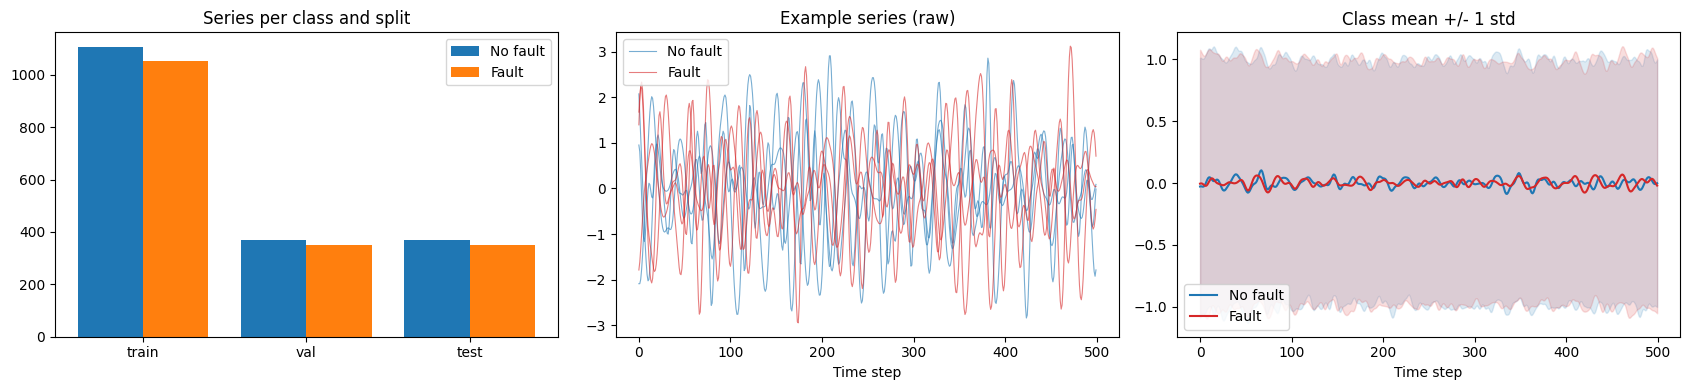

Series length: 500 | total series: 3601 | missing values: 0
Task: classify each whole engine-sound series as fault / no fault (series-level classification, no forecast horizon).


In [9]:
# Data audit: class balance, representative series, class-mean +/- std
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# (a) class balance per split
splits = {"train": y_train, "val": y_val, "test": y_test}
x = np.arange(len(splits))
axes[0].bar(x - 0.2, [(y == 0).sum() for y in splits.values()], 0.4, label=CLASS_NAMES[0])
axes[0].bar(x + 0.2, [(y == 1).sum() for y in splits.values()], 0.4, label=CLASS_NAMES[1])
axes[0].set_xticks(x); axes[0].set_xticklabels(splits.keys())
axes[0].set_title("Series per class and split"); axes[0].legend()

# (b) three example series per class (raw, training set)
for c, colour in ((0, "tab:blue"), (1, "tab:red")):
    for j, i in enumerate(np.where(y_train == c)[0][:3]):
        axes[1].plot(X_train_raw[i], color=colour, alpha=0.6, lw=0.8, label=CLASS_NAMES[c] if j == 0 else None)
axes[1].set_title("Example series (raw)"); axes[1].set_xlabel("Time step"); axes[1].legend()

# (c) class mean +/- 1 std over the training set
for c, colour in ((0, "tab:blue"), (1, "tab:red")):
    m, s = X_train_raw[y_train == c].mean(0), X_train_raw[y_train == c].std(0)
    axes[2].plot(m, color=colour, label=CLASS_NAMES[c])
    axes[2].fill_between(range(len(m)), m - s, m + s, color=colour, alpha=0.15)
axes[2].set_title("Class mean +/- 1 std"); axes[2].set_xlabel("Time step"); axes[2].legend()

plt.tight_layout()
if SAVE_FIGURES:
    plt.savefig("fig_data_audit.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Series length: {SERIES_LEN} | total series: {len(y_all)} | missing values: {int(np.isnan(X_all).sum())}")
print("Task: classify each whole engine-sound series as fault / no fault (series-level classification, no forecast horizon).")

## 2. Evaluation contract and 3. Model development

# Model Building

In [10]:
imputer = SimpleImputer(strategy="median").fit(X_train_raw)
scaler = StandardScaler().fit(imputer.transform(X_train_raw))

# Normalize and impute
def preprocess(X):
    return scaler.transform(imputer.transform(X)).astype("float32")

X_train_flat, X_val_flat, X_test_flat = preprocess(X_train_raw), preprocess(X_val_raw), preprocess(X_test_raw)


In [11]:
# Setup windowing
def make_windows(X, y, window):
    """(N, L) series -> (N * K, window) windows, series-major order, each window carries its series' label."""
    stride = max(1, int(window * (1 - WINDOW_OVERLAP)))
    starts = list(range(0, X.shape[1] - window + 1, stride))
    Xw = np.stack([X[:, s:s + window] for s in starts], axis=1)        # (N, K, window)
    return Xw.reshape(-1, window), np.repeat(y, len(starts)), len(starts)


_WINDOW_CACHE = {}


def get_windows(window):
    if window not in _WINDOW_CACHE:
        _WINDOW_CACHE[window] = {"train": make_windows(X_train_flat, y_train, window),
                                 "val": make_windows(X_val_flat, y_val, window),
                                 "test": make_windows(X_test_flat, y_test, window)}
    return _WINDOW_CACHE[window]


def shape_for(kind, Xw):
    # MLP takes (n, window); CNN / RNN / LSTM / GRU / TCN take (n, window, 1) = samples x time x channels
    return Xw if kind == "flat" else Xw[..., np.newaxis]


# explicit window shapes for every window size used
shape_rows = []
for w in sorted(set(WINDOW_SIZES + [DEFAULT_WINDOW])):
    d = get_windows(w)
    shape_rows.append({"window": w, "stride": max(1, int(w * (1 - WINDOW_OVERLAP))), "windows per series": d["train"][2],
                       "train (MLP)": d["train"][0].shape, "val (MLP)": d["val"][0].shape, "test (MLP)": d["test"][0].shape,
                       "train (sequence models)": d["train"][0].shape + (1,)})
print(pd.DataFrame(shape_rows).to_string(index=False))
print("Series-level targets:", y_train.shape, y_val.shape, y_test.shape,
      "| series probability = mean of its window probabilities, threshold 0.5")


 window  stride  windows per series  train (MLP)   val (MLP)  test (MLP) train (sequence models)
    100      50                   9 (19440, 100) (6480, 100) (6489, 100)         (19440, 100, 1)
    250     125                   3  (6480, 250) (2160, 250) (2163, 250)          (6480, 250, 1)
    500     250                   1  (2160, 500)  (720, 500)  (721, 500)          (2160, 500, 1)
Series-level targets: (2160,) (720,) (721,) | series probability = mean of its window probabilities, threshold 0.5


In [12]:
def scores(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {"acc": accuracy_score(y_true, pred),
            "f1": f1_score(y_true, pred, zero_division=0),
            "auc": roc_auc_score(y_true, prob)}


def compile_model(model):
    model.compile(optimizer=Adam(learning_rate=LEARNING_RATE),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model


def fresh_start():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)


def series_probs(model, Xw, k):
    # window probabilities -> one probability per series (mean over its k windows)
    p = model.predict(Xw, batch_size=256, verbose=0).ravel()
    return p.reshape(-1, k).mean(axis=1)


def save_fig(name):
    if SAVE_FIGURES:
        plt.savefig(name, dpi=150, bbox_inches="tight")


In [13]:
def build_mlp(window, units=64, dropout=0.0):
    return compile_model(Sequential([
        Input(shape=(window,)),
        Dense(units, activation="relu"),
        Dropout(dropout),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ]))


def build_cnn(window, filters=8, kernel_size=7):
    return compile_model(Sequential([
        Input(shape=(window, 1)),
        Conv1D(filters=filters, kernel_size=kernel_size, activation="relu", padding="same"),
        MaxPooling1D(pool_size=4),
        Flatten(),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ]))


def build_recurrent(cell, window, units=32, dropout=0.0):
    # SimpleRNN / LSTM / GRU over the window; the last hidden state feeds the classifier head
    layer = {"SimpleRNN": SimpleRNN, "LSTM": LSTM, "GRU": GRU}[cell]
    return compile_model(Sequential([
        Input(shape=(window, 1)),
        layer(units),
        Dropout(dropout),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ]))


def tcn_block(x, filters, kernel_size, dilation, dropout):
    # residual block: 2 causal dilated convolutions + skip connection
    shortcut = x
    y = Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation, activation="relu")(x)
    y = Dropout(dropout)(y)
    y = Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation, activation="relu")(y)
    y = Dropout(dropout)(y)
    if shortcut.shape[-1] != filters:                      # 1x1 conv so the skip connection has the same channels
        shortcut = Conv1D(filters, 1, padding="same")(shortcut)
    return Activation("relu")(Add()([shortcut, y]))


def build_tcn(window, filters=16, kernel_size=3, dropout=0.1):
    # Receptive field = 1 + 2 * (kernel_size - 1) * (1 + 2 + 4 + 8) = 61 steps (k = 3) or 181 steps (k = 7);
    # global average pooling lets every position contribute even when the window is longer than the receptive field.
    inputs = Input(shape=(window, 1))
    x = inputs
    for level in range(TCN_LEVELS):
        x = tcn_block(x, filters, kernel_size, dilation=2 ** level, dropout=dropout)
    x = GlobalAveragePooling1D()(x)
    x = Dense(16, activation="relu")(x)
    outputs = Dense(1, activation="sigmoid")(x)
    return compile_model(Model(inputs, outputs))


@tf.keras.utils.register_keras_serializable()
class AddPosition(tf.keras.layers.Layer):
    # learnable positional embedding, added to the patch tokens
    def build(self, input_shape):
        self.pos = self.add_weight(name="pos", shape=(1, input_shape[1], input_shape[2]), initializer="random_normal")

    def call(self, x):
        return x + self.pos


def build_transformer(window, d_model=32, heads=2, dropout=0.1, patch=10, blocks=2):
    # Patch embedding (Conv1D, stride = patch) turns W samples into W/patch tokens, then 2 encoder blocks
    # (multi-head self-attention + feed-forward, both residual + LayerNorm), global average pooling, small head.
    inputs = Input(shape=(window, 1))
    x = Conv1D(d_model, patch, strides=patch)(inputs)
    x = AddPosition()(x)
    for _ in range(blocks):
        a = MultiHeadAttention(num_heads=heads, key_dim=max(1, d_model // heads))(x, x)
        x = LayerNormalization()(Add()([x, Dropout(dropout)(a)]))
        f = Dense(d_model * 2, activation="relu")(x)
        f = Dense(d_model)(f)
        x = LayerNormalization()(Add()([x, Dropout(dropout)(f)]))
    x = GlobalAveragePooling1D()(x)
    x = Dense(16, activation="relu")(x)
    outputs = Dense(1, activation="sigmoid")(x)
    return compile_model(Model(inputs, outputs))


MODELS = {
    "MLP": {"build": build_mlp, "kind": "flat"},
    "CNN": {"build": build_cnn, "kind": "seq"},
    "SimpleRNN": {"build": lambda window, **hp: build_recurrent("SimpleRNN", window, **hp), "kind": "seq"},
    "LSTM": {"build": lambda window, **hp: build_recurrent("LSTM", window, **hp), "kind": "seq"},
    "GRU": {"build": lambda window, **hp: build_recurrent("GRU", window, **hp), "kind": "seq"},
    "TCN": {"build": build_tcn, "kind": "seq"},
    "Transformer": {"build": build_transformer, "kind": "seq"},
}


def train_and_validate(name, family, hp, window):
    spec = MODELS[family]
    data = get_windows(window)
    X_tr, y_tr_w, _ = data["train"]
    X_va, y_va_w, k_va = data["val"]
    X_tr, X_va = shape_for(spec["kind"], X_tr), shape_for(spec["kind"], X_va)

    model = spec["build"](window, **hp)
    es = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(X_tr, y_tr_w, validation_data=(X_va, y_va_w),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[es], verbose=0)
    train_seconds = time.perf_counter() - start
    val_prob = series_probs(model, X_va, k_va)
    return {"name": name, "family": family, "hp": hp, "window": window, "kind": spec["kind"],
            "model": model, "history": history.history, "epochs": len(history.history["loss"]),
            "params": model.count_params(), "train_s": train_seconds,
            "val": scores(y_val, val_prob)}


def rank_key(run):
    # HPO ordering: highest validation accuracy, then fewer parameters
    return (-run["val"]["acc"], run["params"])

# Training + Performance

In [14]:
# Majority class

majority_class = int(np.bincount(y_train).argmax())
print("Majority class:", CLASS_NAMES[majority_class])

# Baseline Logistic Regression (same input as the MLP at DEFAULT_WINDOW = 500)
start = time.perf_counter()
logreg = LogisticRegression(C=0.1, max_iter=2000).fit(X_train_flat, y_train)
logreg_seconds = time.perf_counter() - start

# Majority baseline
majority_val_prob = np.full(len(y_val), y_train.mean())
majority_test_prob = np.full(len(y_test), y_train.mean())

logreg_val_prob = logreg.predict_proba(X_val_flat)[:, 1]

print("Validation accuracy:\nmajority:", round(scores(y_val, majority_val_prob)["acc"], 3),
      "| logistic regression:", round(scores(y_val, logreg_val_prob)["acc"], 3))


Majority class: No fault
Validation accuracy:
majority: 0.512 | logistic regression: 0.486


In [15]:
# Train neural models (resumable: families already trained in this kernel are skipped)

if "default_runs" not in globals():
    default_runs = {}

for family in MODELS:
    if family in default_runs:
        print(f"{family}: already trained, skipping (val acc {default_runs[family]['val']['acc']:.3f})")
        continue
    print(f"Training {family} ...", flush=True)
    fresh_start()
    default_runs[family] = train_and_validate(f"{family} (default)", family, DEFAULT_HP[family], DEFAULT_WINDOW)
    print(f"{family}: val acc {default_runs[family]['val']['acc']:.3f}, train {default_runs[family]['train_s']:.1f} s")

default_val_table = pd.DataFrame([{
    "Model": f, "Params": r["params"], "Epochs": r["epochs"], "Train time (s)": round(r["train_s"], 1),
    "Val acc": round(r["val"]["acc"], 4), "Val F1": round(r["val"]["f1"], 4), "Val AUC": round(r["val"]["auc"], 4)}
    for f, r in default_runs.items()]).sort_values("Val acc", ascending=False).reset_index(drop=True)
print(default_val_table.to_string(index=False))

# the family with the best VALIDATION result (acc -> AUC -> fewer params) is the one we tune
best_family = min(default_runs, key=lambda f: (-default_runs[f]["val"]["acc"], -default_runs[f]["val"]["auc"],
                                               default_runs[f]["params"]))
print("Model family selected for HPO (validation evidence only):", best_family)



Training MLP ...

MLP: val acc 0.706, train 9.9 s
Training CNN ...
CNN: val acc 0.864, train 15.5 s
Training SimpleRNN ...
SimpleRNN: val acc 0.650, train 45.0 s
Training LSTM ...
LSTM: val acc 0.546, train 142.4 s
Training GRU ...
GRU: val acc 0.664, train 263.9 s
Training TCN ...
TCN: val acc 0.935, train 129.4 s
Training Transformer ...
Transformer: val acc 0.817, train 36.2 s
      Model  Params  Epochs  Train time (s)  Val acc  Val F1  Val AUC
        TCN    5873      30           129.4   0.9347  0.9343   0.9823
        CNN   16097      16            15.5   0.8639  0.8620   0.9398
Transformer   19585      12            36.2   0.8167  0.8182   0.9111
        MLP   33121       8             9.9   0.7056  0.7056   0.7805
        GRU    3905      25           263.9   0.6639  0.7020   0.7116
  SimpleRNN    1633      10            45.0   0.6500  0.6693   0.7131
       LSTM    4897      14           142.4   0.5458  0.5514   0.5871
Model family selected for HPO (validation evidence only):

## 4. HPO and selection

In [16]:
# Hyperparameter optimization

print("HPO protocol")
print("  family          :", best_family)
print("  search space    :", GRIDS[best_family])
print("  objective       : series-level validation accuracy (tie-break: fewer parameters)")
print(f"  budget          : <= {HPO_MAX_TRIALS} trials, <= {HPO_TIME_BUDGET_S} s")
print(f"  stopping rule   : grid exhausted / trial cap / time budget; per trial early stopping, patience {PATIENCE}")

grid = GRIDS[best_family]
all_trials = [dict(zip(grid.keys(), v)) for v in itertools.product(*grid.values())]
random.Random(SEED).shuffle(all_trials)                    # seeded random order, so a cut-off is not biased by grid order
trials = all_trials[:HPO_MAX_TRIALS]
print(f"  grid size {len(all_trials)} -> running {len(trials)} trials\n")

hpo_rows, best_run = [], None
hpo_start = time.perf_counter()
for i, trial in enumerate(trials, start=1):
    if time.perf_counter() - hpo_start > HPO_TIME_BUDGET_S:
        print("Time budget reached, stopping HPO.")
        break
    hp = dict(trial)
    window = hp.pop("window")
    fresh_start()
    run = train_and_validate(f"{best_family} W={window} {hp}", best_family, hp, window)
    hpo_rows.append({"trial": i, "window": window, **hp, "params": run["params"], "epochs": run["epochs"],
                     "train_s": round(run["train_s"], 1), "val_acc": round(run["val"]["acc"], 4),
                     "val_auc": round(run["val"]["auc"], 4)})
    if best_run is None or rank_key(run) < rank_key(best_run):
        if best_run is not None:
            best_run["model"] = None                       # free the memory of models that are no longer the best
        best_run = run
    else:
        run["model"] = None
    print(f"[trial {i}/{len(trials)}] W={window} {hp} -> val acc {run['val']['acc']:.4f}")

# Report results
hpo_table = pd.DataFrame(hpo_rows)                         # in the order the trials ran
hpo_ranked = hpo_table.sort_values(["val_acc", "params"], ascending=[False, True]).reset_index(drop=True)
hpo_table.to_csv("stage2_hpo_trials.csv", index=False)
print("\nHPO trials ranked by validation accuracy (tie-break: fewer parameters)")
print(hpo_ranked.to_string(index=False))
print("HPO wall time (s):", round(time.perf_counter() - hpo_start, 1))


HPO protocol
  family          : TCN
  search space    : {'window': [100, 250, 500], 'filters': [16, 32], 'kernel_size': [3, 7]}
  objective       : series-level validation accuracy (tie-break: fewer parameters)
  budget          : <= 24 trials, <= 3600 s
  stopping rule   : grid exhausted / trial cap / time budget; per trial early stopping, patience 5
  grid size 12 -> running 12 trials

[trial 1/12] W=250 {'filters': 32, 'kernel_size': 7} -> val acc 0.9542
[trial 2/12] W=250 {'filters': 16, 'kernel_size': 7} -> val acc 0.9583
[trial 3/12] W=100 {'filters': 32, 'kernel_size': 3} -> val acc 0.9458
[trial 4/12] W=500 {'filters': 16, 'kernel_size': 3} -> val acc 0.9347
[trial 5/12] W=500 {'filters': 16, 'kernel_size': 7} -> val acc 0.9556
[trial 6/12] W=250 {'filters': 32, 'kernel_size': 3} -> val acc 0.9444
[trial 7/12] W=500 {'filters': 32, 'kernel_size': 7} -> val acc 0.9583
[trial 8/12] W=100 {'filters': 32, 'kernel_size': 7} -> val acc 0.9486
[trial 9/12] W=250 {'filters': 16, 'kern

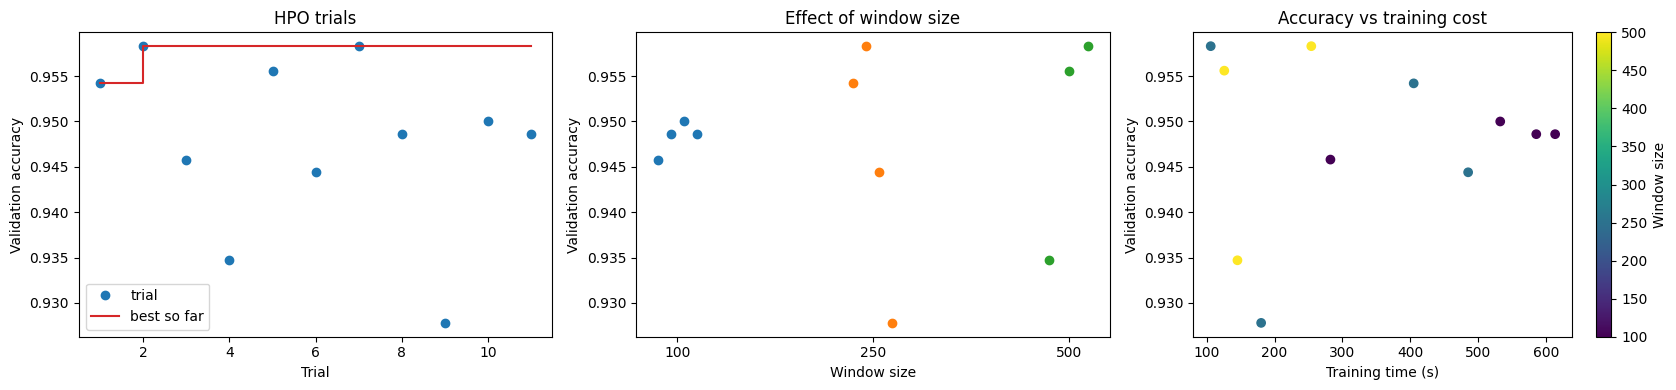

Selected finalist: TCN W=250 {'filters': 16, 'kernel_size': 7}
  validation accuracy 0.9583 (standard error about 0.0074, n = 720 series)
  default TCN (W=500): 0.9347 -> HPO change +2.36 pp
  gap to the runner-up trial: 0.00 pp (within one standard error)
  rule: highest validation accuracy, ties -> fewer parameters. The test set has not been used.


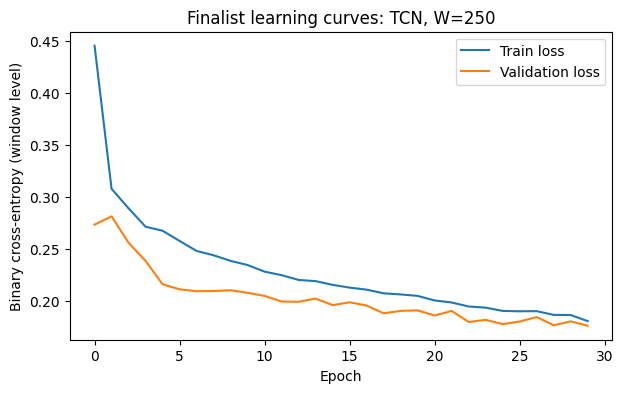

In [17]:
# Analysis of top performing models

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# (a) validation accuracy per trial and best so far
axes[0].plot(hpo_table["trial"], hpo_table["val_acc"], "o", label="trial")
axes[0].step(hpo_table["trial"], hpo_table["val_acc"].cummax(), where="post", color="tab:red", label="best so far")
axes[0].set_xlabel("Trial")
axes[0].set_ylabel("Validation accuracy")
axes[0].set_title("HPO trials")
axes[0].legend()

# (b) validation accuracy by window size
for j, w in enumerate(sorted(hpo_table["window"].unique())):
    vals = hpo_table.loc[hpo_table["window"] == w, "val_acc"]
    axes[1].scatter(np.full(len(vals), j) + np.linspace(-0.1, 0.1, len(vals)), vals)
axes[1].set_xticks(range(hpo_table["window"].nunique()))
axes[1].set_xticklabels(sorted(hpo_table["window"].unique()))
axes[1].set_xlabel("Window size")
axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("Effect of window size")

# (c) accuracy vs training cost
sc_plot = axes[2].scatter(hpo_table["train_s"], hpo_table["val_acc"], c=hpo_table["window"], cmap="viridis")
axes[2].set_xlabel("Training time (s)")
axes[2].set_ylabel("Validation accuracy")
axes[2].set_title("Accuracy vs training cost")
plt.colorbar(sc_plot, ax=axes[2], label="Window size")
plt.tight_layout()
# save_fig("stage2_fig1_hpo_trials.png")
plt.show()

# Evidence for the selection. Validation accuracy has sampling noise, so differences below one standard error are not decisive.
best_val_acc = best_run["val"]["acc"]
val_se = float(np.sqrt(best_val_acc * (1 - best_val_acc) / len(y_val)))
default_val_acc = default_runs[best_family]["val"]["acc"]
print("Selected finalist:", best_run["name"])
print(f"  validation accuracy {best_val_acc:.4f} (standard error about {val_se:.4f}, n = {len(y_val)} series)")
print(f"  default {best_family} (W={DEFAULT_WINDOW}): {default_val_acc:.4f} -> HPO change {100 * (best_val_acc - default_val_acc):+.2f} pp")
if len(hpo_ranked) > 1:
    gap = hpo_ranked.loc[0, "val_acc"] - hpo_ranked.loc[1, "val_acc"]
    print(f"  gap to the runner-up trial: {100 * gap:.2f} pp ({'within' if gap < val_se else 'larger than'} one standard error)")
print("  rule: highest validation accuracy, ties -> fewer parameters. The test set has not been used.")

# Learning curves of the finalist
plt.figure(figsize=(7, 4))
plt.plot(best_run["history"]["loss"], label="Train loss")
plt.plot(best_run["history"]["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy (window level)")
plt.title(f"Finalist learning curves: {best_family}, W={best_run['window']}")
plt.legend()
# save_fig("stage2_fig2_learning_curves.png")
plt.show()


## 5. Final test (locked finalist, test set evaluated once)

In [18]:
# Best model checkpoint

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

best_run["model"].save(f"{CHECKPOINT_DIR}/finalist.keras")
joblib.dump({"imputer": imputer, "scaler": scaler}, f"{CHECKPOINT_DIR}/preprocessing.joblib")
np.savez(f"{CHECKPOINT_DIR}/split_indices.npz", train=idx_train, val=idx_val, test=idx_test)

final_config = {
    "stage": 2,
    "family": best_family,
    "hyperparameters": best_run["hp"],
    "window": best_run["window"],
    "stride": max(1, int(best_run["window"] * (1 - WINDOW_OVERLAP))),
    "window_overlap": WINDOW_OVERLAP,
    "input_kind": best_run["kind"],
    "series_length": SERIES_LEN,
    "series_probability": "mean of window probabilities, threshold 0.5",
    "class_names": CLASS_NAMES,
    "seed": SEED,
    "split": {"test_size": TEST_SIZE, "val_size": VAL_SIZE, "n_train": len(idx_train),
              "n_val": len(idx_val), "n_test": len(idx_test)},
    "training": {"epochs_max": EPOCHS, "batch_size": BATCH_SIZE, "patience": PATIENCE,
                 "learning_rate": LEARNING_RATE, "loss": "binary_crossentropy", "optimizer": "Adam"},
    "hpo": {"objective": "series-level validation accuracy, tie-break fewer parameters",
            "search_space": grid, "trials_run": len(hpo_rows), "max_trials": HPO_MAX_TRIALS,
            "time_budget_s": HPO_TIME_BUDGET_S},
    "validation": {k: float(v) for k, v in best_run["val"].items()},
    "params": int(best_run["params"]),
    "train_seconds": float(best_run["train_s"]),
    "device": DEVICE_NAME,
    "versions": {"python": platform.python_version(), "tensorflow": tf.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__},
    "files": ["finalist.keras", "preprocessing.joblib", "split_indices.npz"],
}
with open(f"{CHECKPOINT_DIR}/finalist_config.json", "w") as f:
    json.dump(final_config, f, indent=2, default=str)
print("Saved to", CHECKPOINT_DIR + "/:", ", ".join(final_config["files"] + ["finalist_config.json"]))
print("To reload: tf.keras.models.load_model(...), joblib.load(...) for imputer + scaler, then window with the saved window / stride.")


Saved to checkpoints/: finalist.keras, preprocessing.joblib, split_indices.npz, finalist_config.json
To reload: tf.keras.models.load_model(...), joblib.load(...) for imputer + scaler, then window with the saved window / stride.


In [19]:
# Summary: final test. The finalist is RELOADED from the saved checkpoint (locked), and the test set is scored once.
cfg = json.load(open(f"{CHECKPOINT_DIR}/finalist_config.json"))
locked_model = tf.keras.models.load_model(f"{CHECKPOINT_DIR}/finalist.keras")
assert locked_model.count_params() == cfg["params"], "checkpoint does not match the saved config"
assert cfg["family"] == best_run["family"] and cfg["window"] == best_run["window"]
best_run["model"] = locked_model                                 # from here on the finalist is the loaded one
print("Loaded locked finalist:", cfg["family"], cfg["hyperparameters"], "| window", cfg["window"], "| params", cfg["params"])

test_prob_store = {}


def timed_test_probs(run):
    X_te, _, k_te = get_windows(run["window"])["test"]
    X_te = shape_for(run["kind"], X_te)
    run["model"].predict(X_te[:BATCH_SIZE], verbose=0)          # warm-up so graph tracing is not counted
    start = time.perf_counter()
    prob = series_probs(run["model"], X_te, k_te)
    return prob, time.perf_counter() - start


# Results for neural network models
def neural_row(label, run):
    prob, infer_s = timed_test_probs(run)
    test_prob_store[label] = prob
    test = scores(y_test, prob)
    return {"Model": label, "Window": run["window"], "Params": run["params"],
            "Train time (s)": round(run["train_s"], 1), "Inference, test set (s)": round(infer_s, 3),
            "Val acc": round(run["val"]["acc"], 4), "Test acc": test["acc"], "Test F1": test["f1"], "Test AUC": test["auc"]}


# Results for logistic regression + majority models
def baseline_row(label, params, seconds, val_prob, predict_test):
    start = time.perf_counter()
    test_prob = predict_test()
    infer_s = time.perf_counter() - start
    test_prob_store[label] = test_prob
    test = scores(y_test, test_prob)
    return {"Model": label, "Window": SERIES_LEN, "Params": params, "Train time (s)": round(seconds, 1),
            "Inference, test set (s)": round(infer_s, 3), "Val acc": round(scores(y_val, val_prob)["acc"], 4),
            "Test acc": test["acc"], "Test F1": test["f1"], "Test AUC": test["auc"]}


tuned_label = f"{best_family} (tuned, W={best_run['window']})"
results = pd.DataFrame(
    [baseline_row("Majority class", 0, 0.0, majority_val_prob, lambda: majority_test_prob),
     baseline_row("Logistic regression", SERIES_LEN + 1, logreg_seconds, logreg_val_prob,
                  lambda: logreg.predict_proba(X_test_flat)[:, 1])]
    + [neural_row(f"{family} (default)", default_runs[family]) for family in MODELS]
    + [neural_row(tuned_label, best_run)]
)

majority_acc = results.loc[results["Model"] == "Majority class", "Test acc"].iloc[0]
logreg_acc = results.loc[results["Model"] == "Logistic regression", "Test acc"].iloc[0]
results["Gain vs majority (pp)"] = ((results["Test acc"] - majority_acc) * 100).round(2)
results["Gain vs logistic reg. (pp)"] = ((results["Test acc"] - logreg_acc) * 100).round(2)
results[["Test acc", "Test F1", "Test AUC"]] = results[["Test acc", "Test F1", "Test AUC"]].round(4)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print(results.to_string(index=False))
print("Training times measured on:", DEVICE_NAME)
results.to_csv("stage2_comparison_table.csv", index=False)

Loaded locked finalist: TCN {'filters': 16, 'kernel_size': 7} | window 250 | params 13105
                Model  Window  Params  Train time (s)  Inference, test set (s)  Val acc  Test acc  Test F1  Test AUC  Gain vs majority (pp)  Gain vs logistic reg. (pp)
       Majority class     500       0             0.0                    0.000   0.5125    0.5132   0.0000    0.5000                   0.00                       -0.69
  Logistic regression     500     501             0.5                    0.004   0.4861    0.5201   0.4956    0.5375                   0.69                        0.00
        MLP (default)     500   33121             9.9                    0.258   0.7056    0.7198   0.7089    0.7797                  20.67                       19.97
        CNN (default)     500   16097            15.5                    0.254   0.8639    0.8488   0.8413    0.9285                  33.56                       32.87
  SimpleRNN (default)     500    1633            45.0                 

Majority class: TN=370  FP=0  FN=351  TP=0
Logistic regression: TN=205  FP=165  FN=181  TP=170
TCN (tuned, W=250): TN=358  FP=12  FN=35  TP=316


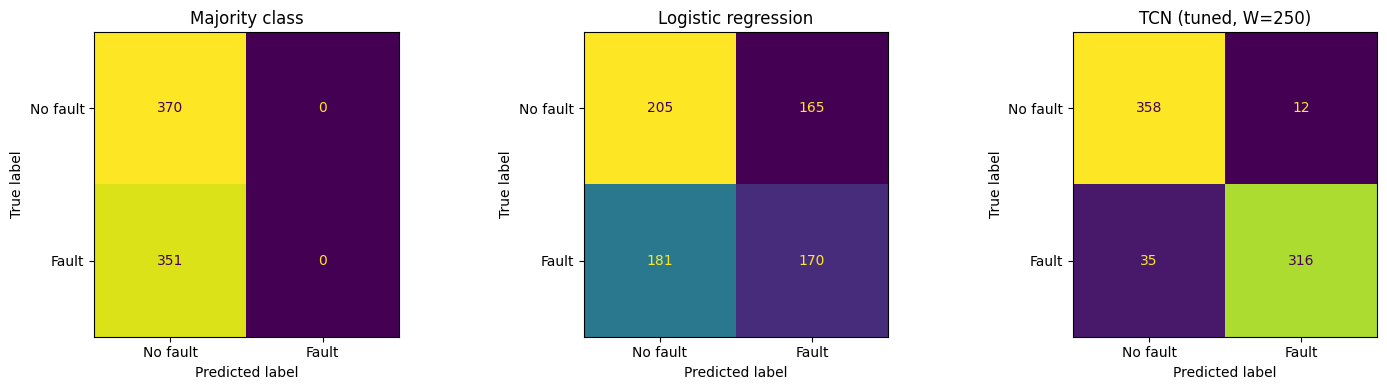

In [20]:
# Confusion matrix

cm_models = [
    ("Majority class", test_prob_store["Majority class"]),
    ("Logistic regression", test_prob_store["Logistic regression"]),
    (tuned_label, test_prob_store[tuned_label]),
]

fig, axes = plt.subplots(1, len(cm_models), figsize=(5 * len(cm_models), 4))
for ax, (name, prob) in zip(axes, cm_models):
    pred = (prob >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])     # rows = true class, columns = predicted class
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False)
    ax.set_title(name)
    print(f"{name}: TN={cm[0, 0]}  FP={cm[0, 1]}  FN={cm[1, 0]}  TP={cm[1, 1]}")
plt.tight_layout()
# save_fig("stage2_fig3_confusion_matrices.png")
plt.show()


## 6. Additional analysis

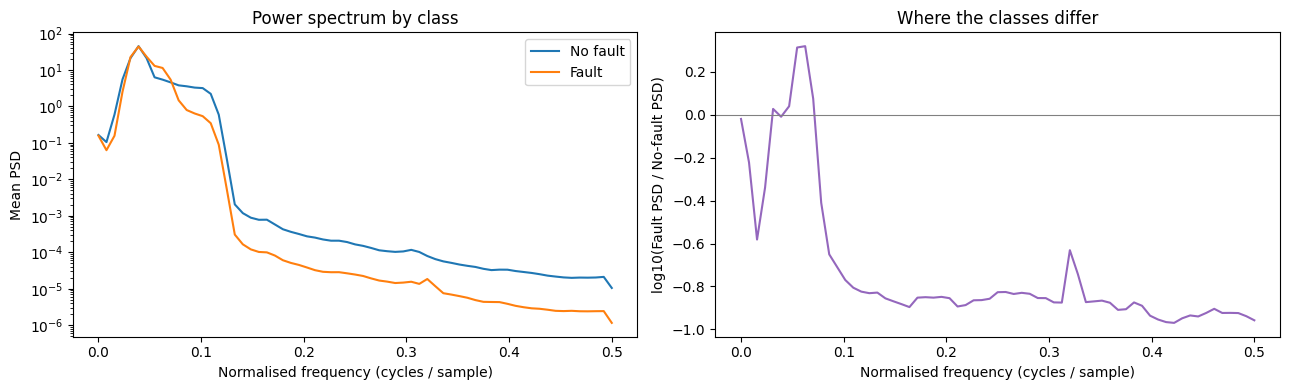

Frequencies with the largest class difference (cycles/sample): [0.422 0.414 0.5  ] | log10 ratio: [-0.97 -0.97 -0.96]


In [21]:
# Frequency analysis: mean power spectral density per class (raw training series), plus where the classes differ most
f, psd0 = welch(X_train_raw[y_train == 0], fs=1.0, nperseg=128, axis=-1)
_, psd1 = welch(X_train_raw[y_train == 1], fs=1.0, nperseg=128, axis=-1)
m0, m1 = psd0.mean(0), psd1.mean(0)
ratio = np.log10(m1 / m0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].semilogy(f, m0, label=CLASS_NAMES[0]); axes[0].semilogy(f, m1, label=CLASS_NAMES[1])
axes[0].set_xlabel("Normalised frequency (cycles / sample)"); axes[0].set_ylabel("Mean PSD"); axes[0].set_title("Power spectrum by class")
axes[0].legend()
axes[1].plot(f, ratio, color="tab:purple"); axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_xlabel("Normalised frequency (cycles / sample)"); axes[1].set_ylabel("log10(Fault PSD / No-fault PSD)")
axes[1].set_title("Where the classes differ")
plt.tight_layout()
save_fig("fig_psd_by_class.png")
plt.show()

top = np.argsort(-np.abs(ratio))[:3]
print("Frequencies with the largest class difference (cycles/sample):", np.round(f[top], 3),
      "| log10 ratio:", np.round(ratio[top], 2))

Overall test error: 0.065 (47 of 721 series)
Error by true class: {'No fault': 0.032, 'Fault': 0.1}
Error by signal amplitude tercile (low / mid / high): [0.036, nan, 0.069]
Error when |p - 0.5| < 0.1 (uncertain): 0.488 (41 series) | when |p - 0.5| >= 0.4 (confident): 0.004 (504 series)


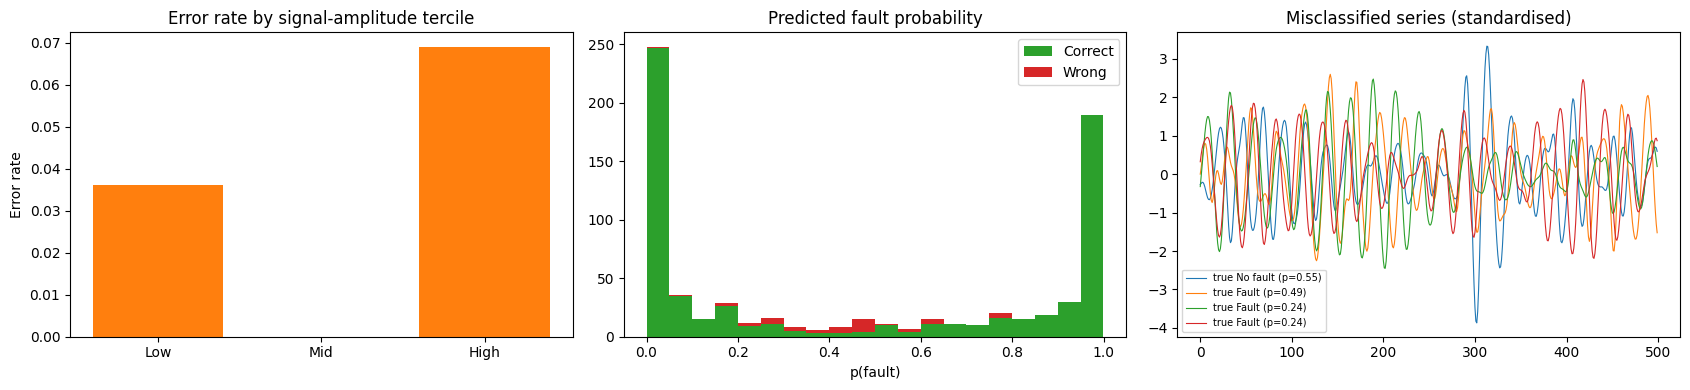

In [22]:
# Failure regime analysis for the locked finalist on the test set
prob = test_prob_store[tuned_label]
pred = (prob >= 0.5).astype(int)
wrong = pred != y_test
energy = X_test_raw.std(axis=1)                                        # raw signal amplitude of each series
terciles = np.digitize(energy, np.quantile(energy, [1 / 3, 2 / 3]))
confidence = np.abs(prob - 0.5)

def rate(mask):
    return round(float(wrong[mask].mean()), 3) if mask.sum() else float("nan")


print(f"Overall test error: {wrong.mean():.3f} ({wrong.sum()} of {len(wrong)} series)")
print("Error by true class:", {CLASS_NAMES[c]: rate(y_test == c) for c in (0, 1)})
print("Error by signal amplitude tercile (low / mid / high):", [rate(terciles == b) for b in range(3)])
print(f"Error when |p - 0.5| < 0.1 (uncertain): {rate(confidence < 0.1)} ({(confidence < 0.1).sum()} series) | "
      f"when |p - 0.5| >= 0.4 (confident): {rate(confidence >= 0.4)} ({(confidence >= 0.4).sum()} series)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(["Low", "Mid", "High"], [np.nan_to_num(rate(terciles == b)) for b in range(3)], color="tab:orange")
axes[0].set_title("Error rate by signal-amplitude tercile"); axes[0].set_ylabel("Error rate")
axes[1].hist([prob[~wrong], prob[wrong]], bins=20, stacked=True, label=["Correct", "Wrong"], color=["tab:green", "tab:red"])
axes[1].set_title("Predicted fault probability"); axes[1].set_xlabel("p(fault)"); axes[1].legend()
for i in np.where(wrong)[0][:4]:
    axes[2].plot(X_test_flat[i], lw=0.8, label=f"true {CLASS_NAMES[y_test[i]]} (p={prob[i]:.2f})")
axes[2].set_title("Misclassified series (standardised)")
if wrong.any():
    axes[2].legend(fontsize=7)
plt.tight_layout()
save_fig("fig_failure_regime.png")
plt.show()

## 7. Reliability and limits

In [23]:
# Empirical error bands: 1000 bootstrap resamples of the test series (accuracy), plus a paired comparison
rng = np.random.default_rng(SEED)
n = len(y_test)
boot_idx = rng.integers(0, n, size=(1000, n))

rows = []
for name, p in test_prob_store.items():
    correct = ((p >= 0.5).astype(int) == y_test)
    accs = correct[boot_idx].mean(axis=1)
    lo, hi = np.percentile(accs, [2.5, 97.5])
    rows.append({"Model": name, "Test acc": round(correct.mean(), 4), "95% CI low": round(lo, 4), "95% CI high": round(hi, 4)})
ci_table = pd.DataFrame(rows)
print(ci_table.to_string(index=False))
ci_table.to_csv("test_accuracy_bootstrap_ci.csv", index=False)

# is the tuned finalist really better than the best default (paired bootstrap on the same resamples)?
best_default = results[results["Model"].str.contains("default")].sort_values("Test acc", ascending=False)["Model"].iloc[0]
c_a = ((test_prob_store[tuned_label] >= 0.5).astype(int) == y_test)
c_b = ((test_prob_store[best_default] >= 0.5).astype(int) == y_test)
diff = c_a[boot_idx].mean(axis=1) - c_b[boot_idx].mean(axis=1)
print(f"\n{tuned_label} minus {best_default}: {diff.mean() * 100:+.2f} pp, 95% CI "
      f"[{np.percentile(diff, 2.5) * 100:+.2f}, {np.percentile(diff, 97.5) * 100:+.2f}] pp")

                Model  Test acc  95% CI low  95% CI high
       Majority class    0.5132      0.4757       0.5479
  Logistic regression    0.5201      0.4840       0.5548
        MLP (default)    0.7198      0.6865       0.7531
        CNN (default)    0.8488      0.8225       0.8766
  SimpleRNN (default)    0.6172      0.5811       0.6533
       LSTM (default)    0.5437      0.5104       0.5811
        GRU (default)    0.6352      0.6006       0.6713
        TCN (default)    0.9376      0.9182       0.9556
Transformer (default)    0.7961      0.7670       0.8252
   TCN (tuned, W=250)    0.9348      0.9168       0.9528

TCN (tuned, W=250) minus TCN (default): -0.30 pp, 95% CI [-2.08, +1.39] pp


    perturbation  TCN (tuned, W=250)  TCN (default)
 noise sigma=0.0              0.9348         0.9376
 noise sigma=0.1              0.9279         0.9431
noise sigma=0.25              0.8974         0.8752
 noise sigma=0.5              0.7642         0.6976
 noise sigma=1.0              0.5146         0.5173
       gain x0.5              0.8710         0.9362
       gain x0.8              0.9251         0.9362
       gain x1.2              0.9417         0.9404
       gain x2.0              0.9348         0.9362
shift 10 samples              0.9307         0.9390
shift 50 samples              0.9334         0.9348


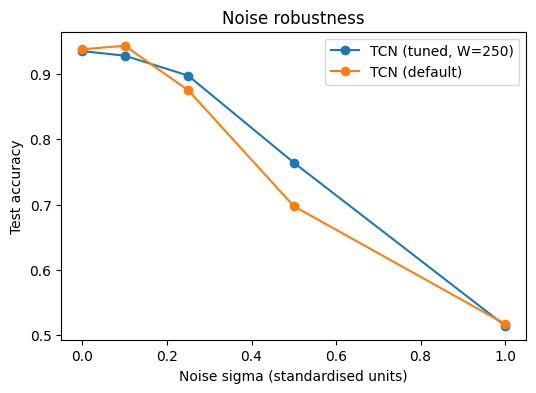

In [24]:
# Robustness: perturb the standardised test series and re-score the finalist and the best default model
rng = np.random.default_rng(SEED)
compare = {tuned_label: best_run, best_default: default_runs[best_default.split(" ")[0]]}


def acc_on(run, X_perturbed):
    Xw, _, k = make_windows(X_perturbed, y_test, run["window"])
    p = series_probs(run["model"], shape_for(run["kind"], Xw), k)
    return scores(y_test, p)["acc"]


rob_rows = []
for sigma in [0.0, 0.1, 0.25, 0.5, 1.0]:                               # additive Gaussian noise (in std units)
    Xn = X_test_flat + rng.normal(0, sigma, X_test_flat.shape).astype("float32")
    rob_rows.append({"perturbation": f"noise sigma={sigma}", **{name: round(acc_on(r, Xn), 4) for name, r in compare.items()}})
for scale in [0.5, 0.8, 1.2, 2.0]:                                     # amplitude / gain drift
    rob_rows.append({"perturbation": f"gain x{scale}", **{name: round(acc_on(r, X_test_flat * scale), 4) for name, r in compare.items()}})
for shift in [10, 50]:                                                 # circular time shift (sample offset)
    rob_rows.append({"perturbation": f"shift {shift} samples", **{name: round(acc_on(r, np.roll(X_test_flat, shift, axis=1)), 4) for name, r in compare.items()}})

rob_table = pd.DataFrame(rob_rows)
print(rob_table.to_string(index=False))
rob_table.to_csv("robustness_table.csv", index=False)

noise_rows = rob_table[rob_table["perturbation"].str.startswith("noise")]
sigmas = [float(s.split("=")[1]) for s in noise_rows["perturbation"]]
plt.figure(figsize=(6, 4))
for name in compare:
    plt.plot(sigmas, noise_rows[name], marker="o", label=name)
plt.xlabel("Noise sigma (standardised units)"); plt.ylabel("Test accuracy"); plt.title("Noise robustness"); plt.legend()
save_fig("fig_noise_robustness.png")
plt.show()

## 9. Reproducibility

Commit the notebook first, then run the next cell so the manifest records the right commit, then commit the files it writes (`run_manifest.json`, `requirements.txt`, `smoke_test.py`, `checkpoints/`).

In [25]:
# Reproducibility: commit, environment, run order, smoke test
def sh(cmd):
    try:
        return subprocess.check_output(cmd, shell=True, stderr=subprocess.STDOUT, text=True).strip()
    except Exception as e:
        return f"unavailable ({e})"


manifest = {
    "git_commit": sh("git rev-parse HEAD"),
    "git_dirty": bool(sh("git status --porcelain")),
    "git_remote": sh("git remote get-url origin"),
    "python": platform.python_version(),
    "tensorflow": tf.__version__, "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
    "device": DEVICE_NAME, "seed": SEED,
    "finalist": tuned_label,
    "test_acc": float(results.loc[results["Model"] == tuned_label, "Test acc"].iloc[0]),
    "run_order": ["pip install -r requirements.txt",
                  "run AISE4010_Project_Group06.ipynb top to bottom (cells in order)",
                  "python smoke_test.py"],
}
json.dump(manifest, open("run_manifest.json", "w"), indent=2)
open("requirements.txt", "w").write(sh(f'"{sys.executable}" -m pip freeze') + "\n")

smoke_code = r'''import json, joblib, numpy as np, pandas as pd, tensorflow as tf

@tf.keras.utils.register_keras_serializable()
class AddPosition(tf.keras.layers.Layer):
    def build(self, input_shape):
        self.pos = self.add_weight(name="pos", shape=(1, input_shape[1], input_shape[2]), initializer="random_normal")
    def call(self, x):
        return x + self.pos

C = "checkpoints"
cfg = json.load(open(f"{C}/finalist_config.json"))
model = tf.keras.models.load_model(f"{C}/finalist.keras")
pre = joblib.load(f"{C}/preprocessing.joblib")
idx = np.load(f"{C}/split_indices.npz")["test"][:8]
data = pd.read_csv("FordA_TRAIN.tsv", sep="\t", header=None).to_numpy(np.float32)
X, y = data[idx, 1:], (data[idx, 0] == 1).astype(int)
X = pre["scaler"].transform(pre["imputer"].transform(X)).astype("float32")
W, stride = cfg["window"], cfg["stride"]
starts = list(range(0, X.shape[1] - W + 1, stride))
Xw = np.stack([X[:, s:s + W] for s in starts], axis=1).reshape(-1, W, 1)
if cfg["input_kind"] == "flat":
    Xw = Xw[..., 0]
prob = model.predict(Xw, verbose=0).ravel().reshape(len(X), -1).mean(axis=1)
assert prob.shape == (8,) and ((prob >= 0) & (prob <= 1)).all()
print("SMOKE TEST PASSED | finalist:", cfg["family"], "| accuracy on 8 test series:", float(((prob >= 0.5) == y).mean()))
'''
open("smoke_test.py", "w").write(smoke_code)

out = subprocess.run([sys.executable, "smoke_test.py"], capture_output=True, text=True)
print(out.stdout[-500:] if out.returncode == 0 else out.stderr[-1500:])
print(json.dumps(manifest, indent=2))

SMOKE TEST PASSED | finalist: TCN | accuracy on 8 test series: 1.0

{
  "git_commit": "eb9ed4b45d489b7e5eac5583a10dac218e879d09",
  "git_dirty": true,
  "git_remote": "https://github.com/IsabellaLoops/AISE_4010_Project.git",
  "python": "3.14.0",
  "tensorflow": "2.22.0-rc0",
  "numpy": "2.4.2",
  "pandas": "3.0.0",
  "sklearn": "1.8.0",
  "device": "CPU",
  "seed": 42,
  "finalist": "TCN (tuned, W=250)",
  "test_acc": 0.9348,
  "run_order": [
    "pip install -r requirements.txt",
    "run AISE4010_Project_Group06.ipynb top to bottom (cells in order)",
    "python smoke_test.py"
  ]
}


> **Note:** the numbers below were written before the Transformer was added. Re-check them against the new results table after a full run.

### CONCLUSION
The finalist, selected on validation evidence only, is the tuned TCN (W=500, 13,105 parameters, 95.1 s training). It reached test accuracy 0.949 (F1 0.947, AUC 0.985): +43.55 pp vs the majority baseline, +42.86 pp vs logistic regression and +8.74 pp vs the default CNN from Stage 1 (16,097 parameters, 9.4 s). HPO gave 16 filters, a kernel size of 7, and a window size of 500.

### FUTURE WORK / UNRESOLVED RISKS
1. Only one model family was tuned, and it was chosen from default-configuration validation scores, so a family that needs tuning to shine (for example the SimpleRNN or the TCN) may have been under-rated. The other families therefore have default hyper-parameters while the finalist has tuned ones: the comparison is fair in data, split and metrics but not in tuning effort.
2. The same validation set is used for early stopping, family selection and HPO, so the best validation score is optimistically biased. Differences smaller than about one standard error (printed in section 13) are not distinguishable, and every result comes from a single seed. Next step: repeat the finalist and the runner-up with several seeds, and compare them on validation again before the final stage.
3. The file has no engine or recording identifier, so near-identical recordings from the same engine may sit in both train and validation or test. Overlapping windows are cut only after the split, so they cannot leak across splits, but an engine-level leak would affect every model. Next step: check with contiguous blocks of the file.